# Review Decoder — чекпоинт 2: исследовательский анализ данных

**Задача:** по английскому отзыву предсказать `Recommended IND`: 1 — recommend,
0 — not recommend. Данные — Women's E-Commerce Clothing Reviews,
[источник Kaggle](https://www.kaggle.com/datasets/nicapotato/womens-ecommerce-clothing-reviews).

Мы исследуем качество данных, связь полей с рекомендацией и особенности текста,
чтобы обосновать будущий baseline. Обучение моделей относится к следующим чекпоинтам.
`Rating`, `Positive Feedback Count`, `Clothing ID` **нельзя подавать в основную модель**;
в этом ноутбуке они используются для понимания данных. Возраст — описательный признак,
а не запланированный вход модели. Индекс CSV — только идентификатор исходной строки.

Ноутбук использует весь датасет для описательного EDA. Отложенная тестовая выборка здесь
не создаётся; будущий тест из этих данных нельзя называть полностью неизученным.
Подбор векторизатора и моделей в дальнейшем выполняется только внутри train,
а одинаковые тексты должны оставаться в одной части разбиения.

Запуск: установить зависимости из `requirements.txt`, затем выполнить из корня
`.venv/Scripts/python.exe scripts/run_eda.py`. Все графики и сводные таблицы
восстанавливаются из локального CSV; загрузок из сети и установки пакетов в ячейках нет.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import os
import platform
import re

DATA_FILENAME = "Womens Clothing E-Commerce Reviews.csv"
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "requirements.txt").is_file() and (p / "external" / DATA_FILENAME).is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Поместите исходный CSV в external/; инструкция: docs/dataset.md")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".local" / "matplotlib"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from scipy.stats import chi2_contingency
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

%matplotlib inline
SEED = 42
np.random.seed(SEED)
FIGURES = ROOT / "reports" / "figures"
TABLES = ROOT / "reports" / "tables"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 140, "font.family": "DejaVu Sans"})
pd.set_option("display.max_columns", 16)
pd.set_option("display.max_colwidth", 85)
LABELS = {0: "not recommend (0)", 1: "recommend (1)"}
COLORS = {0: "#bb4b48", 1: "#367b9c"}
TARGET = "Recommended IND"
CATEGORIES = ["Division Name", "Department Name", "Class Name"]
TEXT_COLUMNS = ["Title", "Review Text"]

def save_table(table, name):
    table.to_csv(TABLES / f"{name}.csv", index=True, encoding="utf-8")
    return table

def show_figure(fig, name):
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight", dpi=140)
    display(fig)
    plt.close(fig)

versions = {name: importlib.metadata.version(name) for name in
            ["numpy", "scipy", "pandas", "matplotlib", "seaborn", "scikit-learn", "nbformat", "nbconvert", "ipykernel", "jupyterlab"]}
display(pd.Series({"Python": platform.python_version(), **versions}, name="version").to_frame())

,version
Python,3.10.4
numpy,2.2.6
scipy,1.15.3
pandas,2.2.3
matplotlib,3.10.3
seaborn,0.13.2
scikit-learn,1.6.1
nbformat,5.10.4
nbconvert,7.16.6
ipykernel,6.29.5


## 1. Паспорт данных и основные статистики

Сначала изучаем исходную таблицу. `raw` сохраняется без очистки: все дальнейшие
преобразования выполняются в копии `audit` и производной текстовой выборке `df`.
Контрольная сумма связывает выводы именно с проверенным файлом.

In [2]:
DATA_PATH = ROOT / "external" / DATA_FILENAME
source_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
EXPECTED_HASH = "bd93cc515747ad1f87b8bc863c9e40da758509e6db6506a96d06976e61e36ee0"
assert source_hash == EXPECTED_HASH, "Версия CSV изменилась: проверьте источник и обновите описание данных."
raw = pd.read_csv(DATA_PATH)
expected = {"Unnamed: 0", "Clothing ID", "Age", "Title", "Review Text", "Rating",
            TARGET, "Positive Feedback Count", *CATEGORIES}
assert set(raw.columns) == expected, f"Неожиданная схема: {raw.columns.tolist()}"
assert raw["Unnamed: 0"].is_unique, "Индекс источника должен однозначно идентифицировать строку."
print(f"Строк: {len(raw):,}; колонок: {raw.shape[1]} (10 содержательных + индекс)")
print(f"SHA-256: {source_hash}")
display(raw.head())
raw.info()
display(save_table(raw.drop(columns="Unnamed: 0").describe(include="all").T, "describe_all"))
audit = raw.rename(columns={"Unnamed: 0": "source_row_id"}).copy(deep=True)
for col in TEXT_COLUMNS + CATEGORIES:
    audit[col] = audit[col].astype("string")
    audit.loc[audit[col].str.fullmatch(r"\s*", na=False), col] = pd.NA

Строк: 23,486; колонок: 11 (10 содержательных + индекс)
SHA-256: bd93cc515747ad1f87b8bc863c9e40da758509e6db6506a96d06976e61e36ee0


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comfortable,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm gl...",5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and really wanted it to work for me. i initi...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time i we...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to the adjustable front tie. it is the p...,5,1,6,General,Tops,Blouses


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Unnamed: 0               23486 non-null  int64 
 1   Clothing ID              23486 non-null  int64 
 2   Age                      23486 non-null  int64 
 3   Title                    19676 non-null  object
 4   Review Text              22641 non-null  object
 5   Rating                   23486 non-null  int64 
 6   Recommended IND          23486 non-null  int64 
 7   Positive Feedback Count  23486 non-null  int64 
 8   Division Name            23472 non-null  object
 9   Department Name          23472 non-null  object
 10  Class Name               23472 non-null  object
dtypes: int64(6), object(5)
memory usage: 2.0+ MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Clothing ID,23486.0,NaN,NaN,NaN,918.118709,203.29898,0.0,861.0,936.0,1078.0,1205.0
Age,23486.0,NaN,NaN,NaN,43.198544,12.279544,18.0,34.0,41.0,52.0,99.0
Title,19676,13993,Love it!,136,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Review Text,22641,22634,Perfect fit and i've gotten so many compliments. i buy all my suits from here now!,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,23486.0,NaN,NaN,NaN,4.196032,1.110031,1.0,4.0,5.0,5.0,5.0
Recommended IND,23486.0,NaN,NaN,NaN,0.822362,0.382216,0.0,1.0,1.0,1.0,1.0
Positive Feedback Count,23486.0,NaN,NaN,NaN,2.535936,5.702202,0.0,0.0,1.0,3.0,122.0
Division Name,23472,3,General,13850,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Department Name,23472,6,Tops,10468,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Class Name,23472,20,Dresses,6319,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
schema = pd.DataFrame([
    ("source_row_id", "Индекс экспорта CSV", "идентификатор строки; не вход модели"),
    ("Clothing ID", "Идентификатор товара", "EDA и анализ концентрации; запрещён модели"),
    ("Age", "Возраст покупательницы", "только описательный EDA"),
    ("Title", "Заголовок отзыва", "дополнительный текстовый эксперимент"),
    ("Review Text", "Основной английский текст", "основной вход модели"),
    ("Rating", "Оценка 1–5", "EDA; запрещён модели"),
    (TARGET, "Рекомендация: 0/1", "целевая переменная"),
    ("Positive Feedback Count", "Число положительных откликов", "EDA; запрещён модели"),
    *[(col, "Уровень категории одежды", "опциональный вход модели") for col in CATEGORIES],
], columns=["field", "meaning", "role"]).set_index("field")
display(save_table(schema, "schema"))

,meaning,role
field,,
source_row_id,Индекс экспорта CSV,идентификатор строки; не вход модели
Clothing ID,Идентификатор товара,EDA и анализ концентрации; запрещён модели
Age,Возраст покупательницы,только описательный EDA
Title,Заголовок отзыва,дополнительный текстовый эксперимент
Review Text,Основной английский текст,основной вход модели
Rating,Оценка 1–5,EDA; запрещён модели
Recommended IND,Рекомендация: 0/1,целевая переменная
Positive Feedback Count,Число положительных откликов,EDA; запрещён модели
Division Name,Уровень категории одежды,опциональный вход модели


**Вывод.** Это текстовая задача с готовой бинарной меткой и описательными полями.
Число уникальных значений `Clothing ID` не делает его непрерывной характеристикой вещи:
арифметический порядок идентификаторов не имеет содержательного смысла.
Изначальные статистики включают строки без текста; для текстовой задачи ниже будет
сформирована отдельная выборка с явным учётом потерь.

## 2. Пропуски и гипотезы об их происхождении

Пропуск — `NaN` или полностью пробельная строка. Считаем долю для каждого поля,
долю всех пустых ячеек без технического индекса и долю неполных строк.
Проверяем, одинаково ли часто отсутствуют текст и заголовок у двух классов.

,missing_n,missing_pct
Title,3810,16.222430
Review Text,845,3.597888
Class Name,14,0.059610
Division Name,14,0.059610
Department Name,14,0.059610
Clothing ID,0,0.000000
Age,0,0.000000
Rating,0,0.000000
Recommended IND,0,0.000000
Positive Feedback Count,0,0.000000


Пустые ячейки: 2.00%; неполные строки: 3,824 (16.28%).


,rows
no missing,19662
Title,2966
"Title, Review Text",843
"Division Name, Department Name, Class Name",13
Review Text,1
"Title, Review Text, Division Name, Department Name, Class Name",1


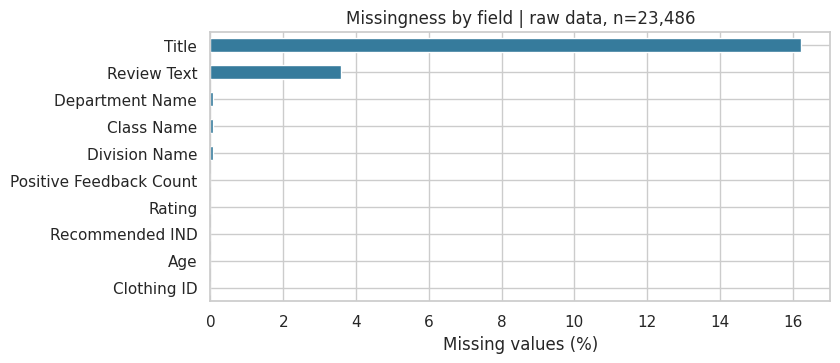

In [4]:
content_columns = [c for c in audit.columns if c != "source_row_id"]
missing = pd.DataFrame({"missing_n": audit[content_columns].isna().sum(),
                        "missing_pct": audit[content_columns].isna().mean() * 100})
display(save_table(missing.sort_values("missing_n", ascending=False), "missing_values"))
cell_missing_pct = 100 * audit[content_columns].isna().to_numpy().mean()
incomplete_rows = int(audit[content_columns].isna().any(axis=1).sum())
print(f"Пустые ячейки: {cell_missing_pct:.2f}%; неполные строки: {incomplete_rows:,} ({incomplete_rows / len(audit):.2%}).")
patterns = audit[content_columns].isna().apply(lambda row: ", ".join(row.index[row]) or "no missing", axis=1)
display(save_table(patterns.value_counts().rename("rows").to_frame(), "missing_patterns"))
fig, ax = plt.subplots(figsize=(8, 3.5))
missing.sort_values("missing_pct")["missing_pct"].plot.barh(ax=ax, color="#367b9c")
ax.set(xlabel="Missing values (%)", title=f"Missingness by field | raw data, n={len(audit):,}")
show_figure(fig, "01_missing_values")

In [5]:
missing_by_target = audit.groupby(TARGET).agg(
    rows=(TARGET, "size"),
    missing_text=("Review Text", lambda s: s.isna().sum()),
    missing_title=("Title", lambda s: s.isna().sum()),
)
missing_by_target["missing_text_pct"] = 100 * missing_by_target.missing_text / missing_by_target.rows
missing_by_target["missing_title_pct"] = 100 * missing_by_target.missing_title / missing_by_target.rows
display(save_table(missing_by_target, "missing_by_target"))
hypothesis_rows = []
for col in TEXT_COLUMNS:
    contingency = pd.crosstab(audit[col].isna(), audit[TARGET]).reindex(index=[False, True], columns=[0, 1], fill_value=0)
    chi2, p_value, _, _ = chi2_contingency(contingency, correction=False)
    hypothesis_rows.append({"field": col, "chi2": chi2, "p_value": p_value,
                            "cramers_v": np.sqrt(chi2 / contingency.to_numpy().sum())})
display(save_table(pd.DataFrame(hypothesis_rows).set_index("field"), "missingness_hypotheses"))
display(audit.assign(missing_text=audit["Review Text"].isna()).groupby("Rating").agg(
    rows=(TARGET, "size"), missing_text_pct=("missing_text", lambda s: 100 * s.mean())))
display(audit.assign(missing_text=audit["Review Text"].isna()).groupby("Department Name", dropna=False).agg(
    rows=(TARGET, "size"), missing_text_pct=("missing_text", lambda s: 100 * s.mean())))
print("Строк без текста, но с заголовком:", int((audit["Review Text"].isna() & audit["Title"].notna()).sum()))
print("Категории отсутствуют совместно:", bool(audit[CATEGORIES].isna().nunique(axis=1).eq(1).all()))
display(Markdown(f"**Наблюдение:** основной текст отсутствует у {missing_by_target.loc[0, 'missing_text_pct']:.2f}% класса 0 и {missing_by_target.loc[1, 'missing_text_pct']:.2f}% класса 1. Всего пустых ячеек {cell_missing_pct:.2f}%, но неполных строк {incomplete_rows / len(audit):.2%}: эти показатели описывают разные свойства данных."))

,rows,missing_text,missing_title,missing_text_pct,missing_title_pct
Recommended IND,,,,,
0,4172,71,597,1.701822,14.309684
1,19314,774,3213,4.007456,16.635601


,chi2,p_value,cramers_v
field,,,
Title,13.656909,2.194324e-04,0.024114
Review Text,52.584050,4.122236e-13,0.047318


,rows,missing_text_pct
Rating,,
1,842,2.494062
2,1565,1.022364
3,2871,1.671891
4,5077,3.328737
5,13131,4.500800


,rows,missing_text_pct
Department Name,,
Bottoms,3799,3.606212
Dresses,6319,2.753600
Intimate,1735,4.726225
Jackets,1032,2.906977
Tops,10468,4.012228
Trend,119,0.840336
<NA>,14,7.142857


Строк без текста, но с заголовком: 1


Категории отсутствуют совместно: True


**Наблюдение:** основной текст отсутствует у 1.70% класса 0 и 4.01% класса 1. Всего пустых ячеек 2.00%, но неполных строк 16.28%: эти показатели описывают разные свойства данных.

**Интерпретация.** Утверждение «пропуски случайны» нужно проверять по долям внутри
каждого класса, а не по абсолютным числам. Таблица и χ² проверяют связь пропуска с таргетом;
малое p-value не устанавливает причину пропуска и не доказывает сильный эффект — для этого
рядом приведён Cramér's V. Наблюдения одного магазина и повторные отзывы могут быть зависимы.

Гипотеза: часть покупательниц ставила оценку/рекомендацию без текста; данные совместимы
с таким механизмом, но не содержат формы сбора или объяснений автора. Почти полное совместное
отсутствие текста и заголовка означает, что подстановка заголовка не восстановит большинство
пустых отзывов. Для text-only baseline исключаем такие строки; заголовки не являются
обязательными, категории допускают `unknown`. Восстанавливать рекомендацию по рейтингу нельзя.

## 3. Ошибочные значения и повторяющиеся записи

Проверяем домены, а не просто необычность значения. Возраст 99 лет или большое число
откликов сами по себе не ошибки. Возраст выше 120 отмечался бы как кандидат на ручную
проверку, а не автоматически удалялся. Полный дубль не включает индекс экспорта.
Для сравнения текстов отдельно нормализуем регистр и пробелы, сохраняя оригинал.

In [6]:
numeric_columns = ["Clothing ID", "Age", "Rating", TARGET, "Positive Feedback Count"]
numeric = audit[numeric_columns].apply(pd.to_numeric, errors="coerce")
invalid = pd.DataFrame(index=audit.index)
invalid[TARGET] = ~numeric[TARGET].isin([0, 1])
invalid["Rating"] = ~numeric["Rating"].isin([1, 2, 3, 4, 5])
invalid["Age"] = numeric["Age"].isna() | numeric["Age"].le(0) | numeric["Age"].gt(120)
for col in ["Clothing ID", "Positive Feedback Count"]:
    invalid[col] = numeric[col].isna() | numeric[col].lt(0) | numeric[col].mod(1).ne(0)
display(save_table(invalid.sum().rename("invalid_or_review_candidates").to_frame(), "domain_checks"))
display(numeric.agg(["min", "max", "nunique"]).T)
assert not invalid.any().any(), "Найдены ошибки/кандидаты: разберите строки до продолжения."
full_columns = [c for c in audit.columns if c != "source_row_id"]
full_duplicate_mask = audit.duplicated(subset=full_columns, keep="first")
audit["text_group"] = audit["Review Text"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
text_group_stats = audit.dropna(subset=["text_group"]).groupby("text_group").agg(
    rows=(TARGET, "size"), labels=(TARGET, "nunique"), items=("Clothing ID", "nunique"))
repeated_texts = text_group_stats[text_group_stats.rows.gt(1)]
print("Полных повторов без индекса:", int(full_duplicate_mask.sum()))
print("Повторяющихся групп текста:", len(repeated_texts), "; групп с конфликтами таргета:", int(repeated_texts.labels.gt(1).sum()))
display(repeated_texts.reset_index().assign(text_group=lambda t: t.text_group.str.slice(0, 100)))
display(audit.loc[audit.duplicated(subset=full_columns, keep=False) & audit["Review Text"].notna(),
                  ["source_row_id", "Clothing ID", TARGET, "Age", "Rating", "Review Text"]])
display(Markdown(f"**Результат проверки:** ошибок по заданным доменам не найдено; {int(full_duplicate_mask.sum())} полных повторов и {len(repeated_texts)} групп повторного текста требуют разных правил. Конфликтующих меток в текстовых группах: {int(repeated_texts.labels.gt(1).sum())}."))

,invalid_or_review_candidates
Recommended IND,0
Rating,0
Age,0
Clothing ID,0
Positive Feedback Count,0


,min,max,nunique
Clothing ID,0,1205,1206
Age,18,99,77
Rating,1,5,5
Recommended IND,0,1,2
Positive Feedback Count,0,122,82


Полных повторов без индекса: 21
Повторяющихся групп текста: 6 ; групп с конфликтами таргета: 0


,text_group,rows,labels,items
0,"i bought this shirt at the store and after going home and trying it on, i promptl...",2,1,2
1,i purchased this and another eva franco dress during retailer's recent 20% off sa...,2,1,1
2,"lightweight, soft cotton top and shorts. i think it's meant to be a beach cover-u...",2,1,2
3,"love, love these jeans. being short they come right to my ankle. super soft and d...",2,1,1
4,perfect fit and i've gotten so many compliments. i buy all my suits from here now!,3,1,3
5,"the sweater and skirt are so pretty! they're really soft and have such an easy, c...",2,1,2


,source_row_id,Clothing ID,Recommended IND,Age,Rating,Review Text
9447,9447,1022,1,37,5,"Love, love these jeans. being short they come right to my ankle. super soft and d..."
21888,21888,1022,1,37,5,"Love, love these jeans. being short they come right to my ankle. super soft and d..."


**Результат проверки:** ошибок по заданным доменам не найдено; 21 полных повторов и 6 групп повторного текста требуют разных правил. Конфликтующих меток в текстовых группах: 0.

### Политика подготовки

1. Исключить строки без основного текста из текстовой выборки, сохранив их в аудите.
2. Исключить точные совпадения всех содержательных полей среди оставшихся строк.
   Это консервативное предположение о повторном экспорте: без идентификатора отзыва
   техническую природу дубля доказать нельзя. Показываем конкретные строки и размер потери.
3. Не удалять отзывы только из-за совпадения текста у разных записей. Сохранить
   `text_group` для будущего разбиения без пересечения одинаковых текстов.
4. Заполнить отсутствующий заголовок пустой строкой, категорию — `unknown`.
   Сохранить признаки исходного пропуска для аудита, не заявляя их входами модели.
5. Числовые поля прошли проверки доменов; необоснованной импутации или обрезки нет.
   `Initmates` остаётся исходным написанием: автоматическое исправление не требуется EDA.

In [7]:
ledger = [{"stage": "raw", "rows": len(audit), "removed": 0, "recommend_pct": 100 * audit[TARGET].mean()}]
df = audit.loc[audit["Review Text"].notna()].copy()
ledger.append({"stage": "nonempty_review", "rows": len(df), "removed": len(audit) - len(df),
               "recommend_pct": 100 * df[TARGET].mean()})
before_dedup = len(df)
df = df.drop_duplicates(subset=full_columns, keep="first").copy()
ledger.append({"stage": "exact_duplicate_removed", "rows": len(df), "removed": before_dedup - len(df),
               "recommend_pct": 100 * df[TARGET].mean()})
for col in TEXT_COLUMNS + CATEGORIES:
    df[f"missing_{col}"] = df[col].isna()
for col in CATEGORIES:
    df[col] = df[col].fillna("unknown")
df["Title"] = df["Title"].fillna("")
df["class_label"] = df[TARGET].map(LABELS)
df["review_chars"] = df["Review Text"].str.len()
df["review_words"] = df["Review Text"].str.split().str.len()
df["title_chars"] = df["Title"].str.len()
df["title_words"] = df["Title"].str.split().str.len()
display(save_table(pd.DataFrame(ledger).set_index("stage"), "cleaning_ledger"))
assert ledger[0]["rows"] - sum(row["removed"] for row in ledger[1:]) == len(df)
assert df["source_row_id"].is_unique and df["Review Text"].notna().all()
assert df[TARGET].isin([0, 1]).all() and df["review_words"].gt(0).all()
assert not df.duplicated(subset=full_columns).any()
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == source_hash
# This local manifest preserves groups for a future split; it is not a train/test split.
manifest = df[["source_row_id", TARGET]].copy()
manifest["text_group_sha256"] = df["text_group"].map(lambda s: hashlib.sha256(s.encode("utf-8")).hexdigest())
(ROOT / "data" / "processed").mkdir(parents=True, exist_ok=True)
manifest.to_csv(ROOT / "data" / "processed" / "review_manifest.csv", index=False)

,rows,removed,recommend_pct
stage,,,
raw,23486,0,82.236226
nonempty_review,22641,845,81.886842
exact_duplicate_removed,22640,1,81.886042


## 4. Баланс классов

Показываем исходную и подготовленную выборку: удаление строк без текста может изменить
баланс, если пропуски связаны с рекомендацией. Не применяем ресэмплинг на этапе EDA.

,raw,text,raw_pct,text_pct
Recommended IND,,,,
0,4172,4101,17.763774,18.113958
1,19314,18539,82.236226,81.886042


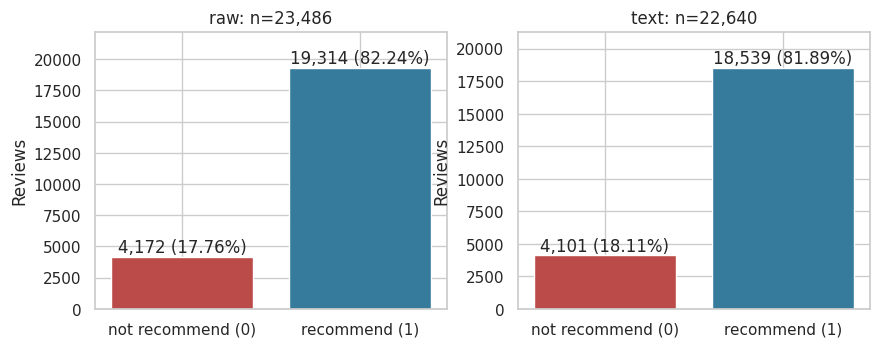

**Наблюдение:** после обработки доля класса 0 — 18.11% вместо исходных 17.76%. Доля большинства 81.89% — ориентир для accuracy, а не результат оценки будущего классификатора.

In [8]:
balances = pd.concat({"raw": audit[TARGET].value_counts().reindex([0, 1]),
                      "text": df[TARGET].value_counts().reindex([0, 1])}, axis=1)
for name in ["raw", "text"]:
    balances[f"{name}_pct"] = 100 * balances[name] / balances[name].sum()
display(save_table(balances, "class_balance"))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, name in zip(axes, ["raw", "text"]):
    values = balances[name]
    ax.bar([LABELS[i] for i in values.index], values, color=[COLORS[i] for i in values.index])
    for x, (label, count) in enumerate(values.items()):
        ax.text(x, count, f"{count:,} ({balances.loc[label, name + '_pct']:.2f}%)", ha="center", va="bottom")
    ax.set(title=f"{name}: n={values.sum():,}", ylabel="Reviews")
    ax.set_ylim(0, values.max() * 1.15)
show_figure(fig, "02_class_balance")
display(Markdown(f"**Наблюдение:** после обработки доля класса 0 — {balances.loc[0, 'text_pct']:.2f}% вместо исходных {balances.loc[0, 'raw_pct']:.2f}%. Доля большинства {balances.loc[1, 'text_pct']:.2f}% — ориентир для accuracy, а не результат оценки будущего классификатора."))

**Вывод.** Постоянный ответ «рекомендую» уже даёт высокую accuracy, но не находит
ни одного отрицательного примера. Поэтому основная метрика — Macro-F1, дополнительно
F1 класса `not recommend`. Для PR-AUC нужно задать `y_negative = (y == 0)` и использовать
вероятность класса 0; для ROC-AUC также явно указывать положительный класс.
Численный baseline `DummyClassifier` будет обучен на следующем чекпоинте.

## 5. Числовые поля, выбросы и противоречивые оценки

Проверяем каждый числовой признак и связь с таргетом. Для количества откликов из-за
длинного хвоста используем `log1p` только на рисунке. IQR отмечает необычные значения,
но не доказывает ошибку, особенно у дискретного рейтинга и несимметричных счётчиков.

Age                                      Rating            \
                 count       mean median        std min max  count      mean   
Recommended IND                                                                
0                 4101  42.383809   40.0  11.794748  19  94   4101  2.303341   
1                18539  43.479044   41.0  12.433456  18  99  18539  4.599439   

                 ... review_words      title_chars                    \
                 ...          min  max       count       mean median   
Recommended IND  ...                                                   
0                ...            3  115        4101  17.658376   17.0   
1                ...            2  115       18539  16.360537   15.0   

                                    
                       std min max  
Recommended IND                     
0                11.891567   0  52  
1                10.793455   0  51  

[2 rows x 36 columns]

,q1,q3,lower,upper,iqr_candidates,candidate_pct
field,,,,,,
Age,34.0,52.0,7.0,79.0,108,0.477032
Rating,4.0,5.0,2.5,6.5,2370,10.468198
Positive Feedback Count,0.0,3.0,-4.5,7.5,2147,9.483216
review_chars,186.0,459.0,-223.5,868.5,0,0.000000
review_words,36.0,88.0,-42.0,166.0,0,0.000000
title_chars,9.0,23.0,-12.0,44.0,378,1.669611


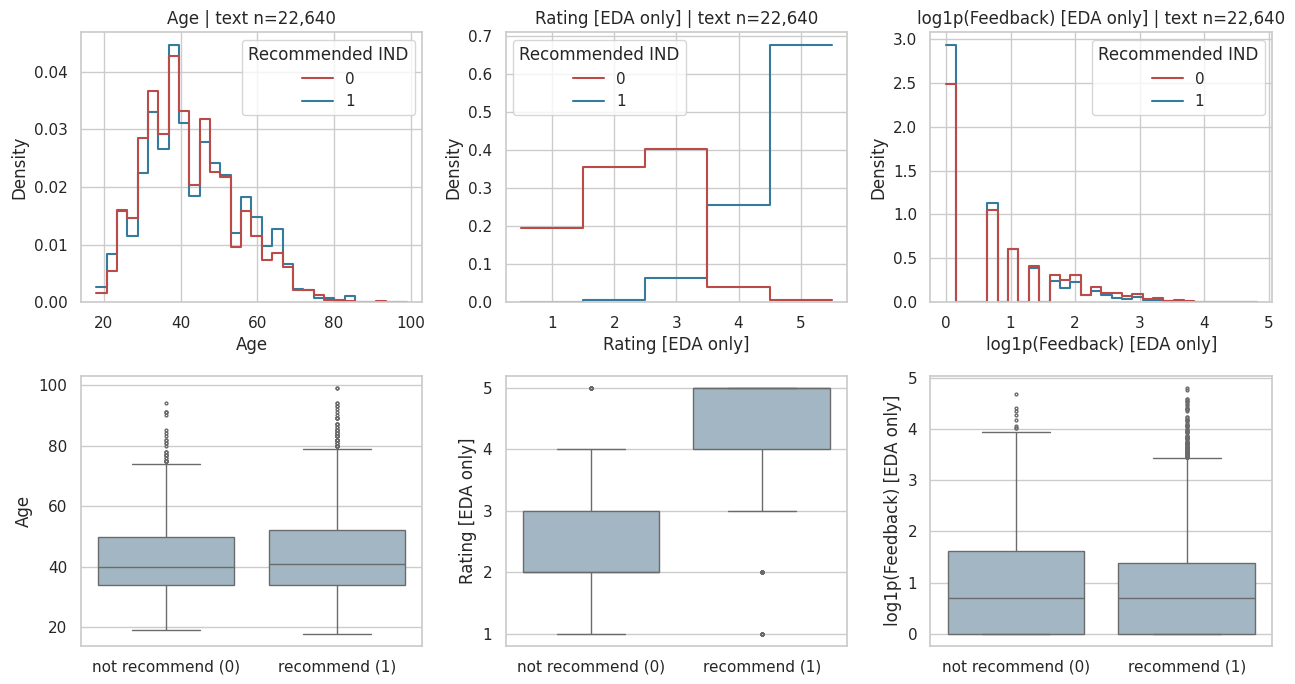

,source_row_id,Age,Rating,Positive Feedback Count,Recommended IND,Review Text
7218,7218,34,3,122,1,I loved the lace detailing all over this dress and the fact it had pockets and wa...
8327,8327,99,5,1,1,I love the weight of the material; sometimes crinkled gauze looks cheap; this doe...
11545,11545,99,4,4,1,"Great quality, i didn't expect the neck to be so wide but it still looks nice."


Recommended IND,0,1,recommend_pct
Rating,,,
1,806,15,1.827040
2,1455,94,6.068431
3,1653,1170,41.445271
4,164,4744,96.658517
5,23,12516,99.816572


Низкий рейтинг с рекомендацией или высокий без неё: 296 (1.31%)


,source_row_id,Rating,Recommended IND,Title,Review Text
21966,21966,4,0,Cute,Definitely cute and good fit but the distressing at knee is open and will probabl...
13324,13324,2,1,Not for everyone,"If these jeans work for you, you're a lucky girl! the fabric is really thick and ..."
8095,8095,4,0,Middle seam off,This top is very cute. but the middle seam in off center near the bottom and caus...
7850,7850,1,1,,"This is so close to perfect, but there's a seam down the middle of the back and t..."
21213,21213,4,0,Cute but didn't work,I love this dress. it's an unusual material and really adorable in person. the pr...
943,943,4,0,"Pretty pattern, weird texture",I love the design and pattern of this top. it runs big so an xs was roomy on me b...


**Наблюдение:** IQR отмечает 2,370 рейтингов 1–2 как низкие выбросы из-за преобладания высоких оценок. Удаление этих строк исказило бы задачу. Возраст достигает 99 лет, отклики — 122; оба значения допустимы по домену и сохранены. Явных несовпадений высокой/низкой оценки и рекомендации — 296.

In [9]:
numeric_features = ["Age", "Rating", "Positive Feedback Count", "review_chars", "review_words", "title_chars"]
display(save_table(df.groupby(TARGET)[numeric_features].agg(["count", "mean", "median", "std", "min", "max"]), "numeric_by_target"))
outlier_rows = []
for col in numeric_features:
    q1, q3 = df[col].quantile([0.25, 0.75])
    lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    count = int((df[col].lt(lower) | df[col].gt(upper)).sum())
    outlier_rows.append({"field": col, "q1": q1, "q3": q3, "lower": lower, "upper": upper,
                         "iqr_candidates": count, "candidate_pct": 100 * count / len(df)})
display(save_table(pd.DataFrame(outlier_rows).set_index("field"), "outlier_candidates"))
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for i, col in enumerate(["Age", "Rating", "Positive Feedback Count"]):
    plotting = df.assign(value=np.log1p(df[col]) if col == "Positive Feedback Count" else df[col])
    label = {"Age": "Age", "Rating": "Rating [EDA only]", "Positive Feedback Count": "log1p(Feedback) [EDA only]"}[col]
    sns.histplot(data=plotting, x="value", hue=TARGET, hue_order=[0, 1], palette=COLORS,
                 stat="density", common_norm=False, element="step", fill=False,
                 discrete=(col == "Rating"), bins=30, ax=axes[0, i])
    axes[0, i].set(title=f"{label} | text n={len(df):,}", xlabel=label)
    sns.boxplot(data=plotting, x="class_label", y="value", order=[LABELS[0], LABELS[1]],
                color="#9db9c8", ax=axes[1, i], fliersize=2)
    axes[1, i].set(xlabel="", ylabel=label)
fig.tight_layout()
show_figure(fig, "03_numeric_distributions")
display(df.loc[df["Age"].eq(df["Age"].max()) | df["Positive Feedback Count"].eq(df["Positive Feedback Count"].max()),
               ["source_row_id", "Age", "Rating", "Positive Feedback Count", TARGET, "Review Text"]].head(6))
rating_target = pd.crosstab(df["Rating"], df[TARGET]).reindex(columns=[0, 1], fill_value=0)
rating_target["recommend_pct"] = 100 * rating_target[1] / rating_target[[0, 1]].sum(axis=1)
display(save_table(rating_target, "rating_target"))
contradictions = df[(df["Rating"].le(2) & df[TARGET].eq(1)) | (df["Rating"].ge(4) & df[TARGET].eq(0))]
print(f"Низкий рейтинг с рекомендацией или высокий без неё: {len(contradictions):,} ({len(contradictions) / len(df):.2%})")
display(contradictions[["source_row_id", "Rating", TARGET, "Title", "Review Text"]].sample(min(6, len(contradictions)), random_state=SEED))
display(Markdown(f"**Наблюдение:** IQR отмечает {int(df.Rating.lt(2.5).sum()):,} рейтингов 1–2 как низкие выбросы из-за преобладания высоких оценок. Удаление этих строк исказило бы задачу. Возраст достигает {int(df.Age.max())} лет, отклики — {int(df['Positive Feedback Count'].max())}; оба значения допустимы по домену и сохранены. Явных несовпадений высокой/низкой оценки и рекомендации — {len(contradictions)}."))

Товаров: 1,206; медиана отзывов на товар: 2.0; максимум: 1,024.
На 10 самых обсуждаемых товаров приходится 25.17% отзывов.


,reviews_per_item
count,1206.000000
mean,19.474295
std,69.009764
min,1.000000
25%,1.000000
50%,2.000000
75%,6.750000
max,1024.000000


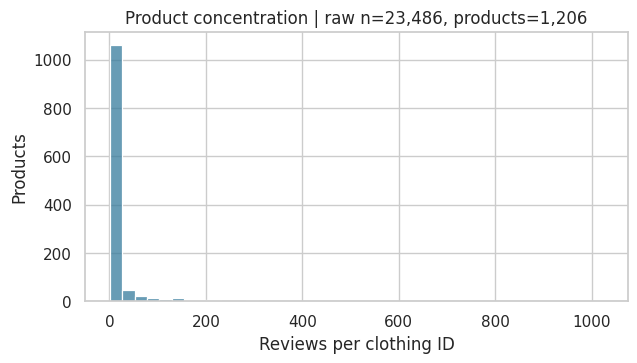

In [10]:
item_counts = audit.groupby("Clothing ID").size().sort_values(ascending=False)
print(f"Товаров: {len(item_counts):,}; медиана отзывов на товар: {item_counts.median():.1f}; максимум: {item_counts.max():,}.")
print(f"На 10 самых обсуждаемых товаров приходится {item_counts.head(10).sum() / len(audit):.2%} отзывов.")
display(save_table(item_counts.describe().rename("reviews_per_item").to_frame(), "item_concentration"))
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(item_counts, bins=40, ax=ax, color="#367b9c")
ax.set(xlabel="Reviews per clothing ID", ylabel="Products", title=f"Product concentration | raw n={len(audit):,}, products={len(item_counts):,}")
show_figure(fig, "04_item_concentration")

**Решение.** Корректные крайние возраст/отклики сохраняем; IQR не используется как
автоматический фильтр. Оценка и рекомендация связаны, но не тождественны: несовпадения
не являются доказательством неверной метки. Переписывать таргет по рейтингу нельзя.
Отзывы сконцентрированы на популярных товарах; поэтому качество на новых товарах и
на новых отзывах уже известных товаров — разные сценарии будущей оценки. `Clothing ID`
можно использовать для диагностического группирования, но нельзя давать основной модели.

## 6. Категории одежды и доли рекомендаций

Рассматриваем все три уровня категорий. Для каждой группы выводим `n` и 95%-интервал
Wilson для доли рекомендаций. Интервал описательный, предполагает независимость
наблюдений; зависимость отзывов одного товара может делать его слишком узким.
Группы с `n < 30` выделяем как малые, а не как надёжных лидеров рейтинга.

,n,recommend_n,recommend_pct,wilson_low_pct,wilson_high_pct,small_group
Division Name,,,,,,
General,13364,10871,81.345406,80.675970,81.996825,False
General Petite,7837,6446,82.250861,81.389179,83.080941,False
Initmates,1426,1209,84.782609,82.825002,86.553312,False
unknown,13,13,100.000000,77.189816,100.000000,True


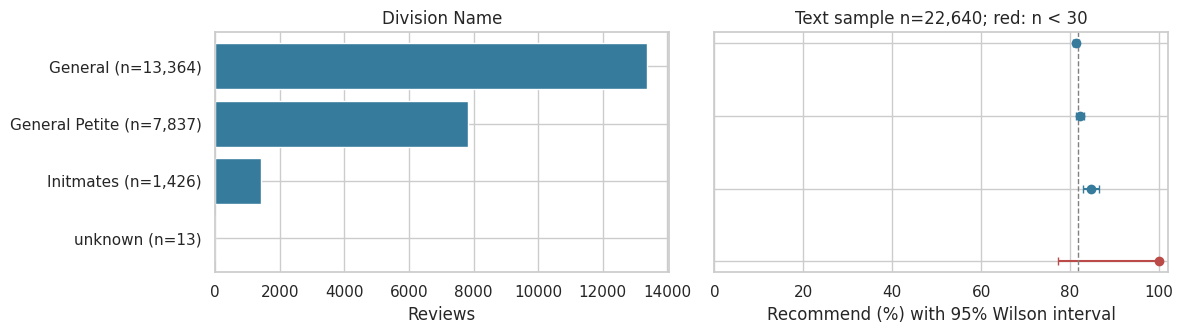

,n,recommend_n,recommend_pct,wilson_low_pct,wilson_high_pct,small_group
Department Name,,,,,,
Tops,10048,8146,81.070860,80.293065,81.824905,False
Dresses,6145,4948,80.520749,79.511578,81.491782,False
Bottoms,3661,3110,84.949467,83.754583,86.071082,False
Intimate,1653,1399,84.633999,82.815365,86.292026,False
Jackets,1002,835,83.333333,80.899343,85.512704,False
Trend,118,88,74.576271,66.030905,81.571884,False
unknown,13,13,100.000000,77.189816,100.000000,True


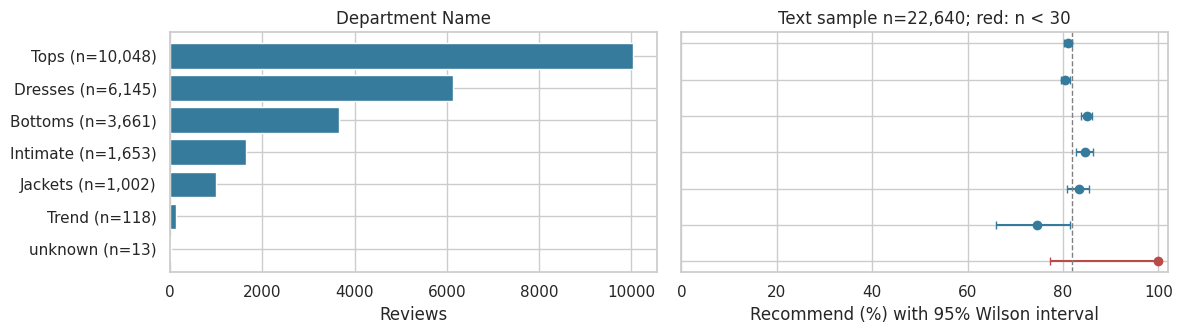

,n,recommend_n,recommend_pct,wilson_low_pct,wilson_high_pct,small_group
Class Name,,,,,,
Dresses,6145,4948,80.520749,79.511578,81.491782,False
Knits,4626,3758,81.236489,80.085653,82.335489,False
Blouses,2983,2406,80.657057,79.200526,82.034727,False
Sweaters,1380,1100,79.710145,77.507170,81.748167,False
Pants,1350,1124,83.259259,81.173917,85.155852,False
Jeans,1103,970,87.941976,85.887328,89.733248,False
Fine gauge,1059,882,83.286119,80.919493,85.412122,False
Skirts,903,760,84.163898,81.638599,86.399744,False
Jackets,683,576,84.333821,81.416633,86.866942,False


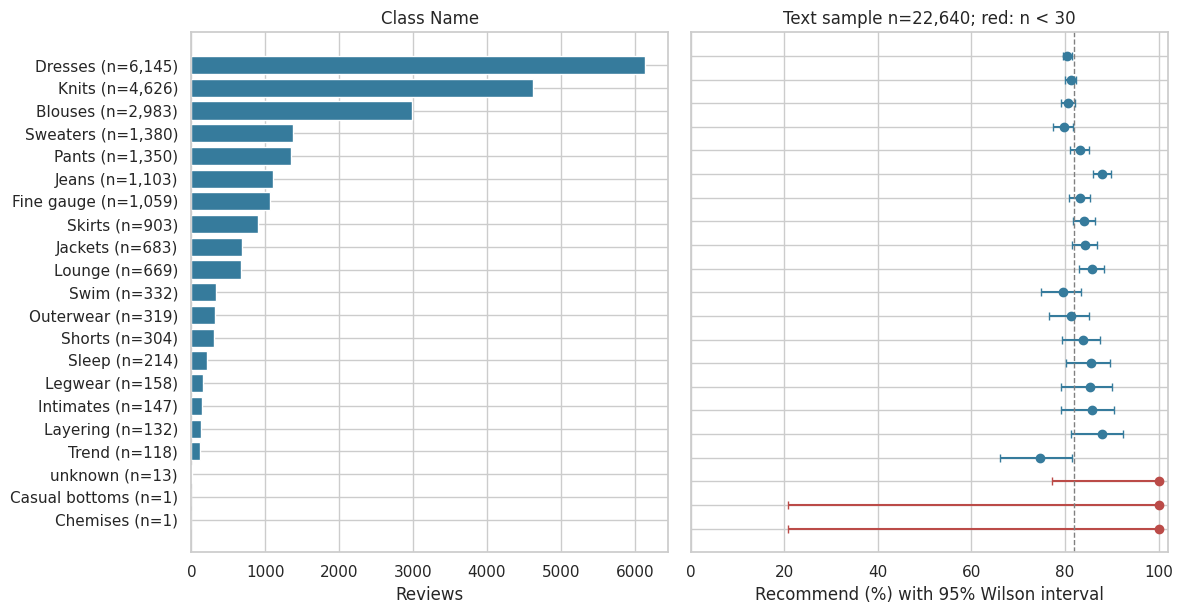

,departments,divisions
Class Name,,
Blouses,1,2
Casual bottoms,1,1
Chemises,1,1
Dresses,1,2
Fine gauge,1,2
Intimates,1,1
Jackets,1,2
Jeans,1,2
Knits,1,2


Recommended IND,0,1,All
Department Name,,,
Bottoms,551,3110,3661
Dresses,1197,4948,6145
Intimate,254,1399,1653
Jackets,167,835,1002
Tops,1902,8146,10048
Trend,30,88,118
unknown,0,13,13
All,4101,18539,22640


**Наблюдение:** доля рекомендаций у Dresses — 80.52% (n=6,145), у Bottoms — 84.95% (n=3,661), у Trend — 74.58% (n=118). У Casual bottoms и Chemises в текстовой выборке по одному примеру; 100% там не является надёжной оценкой.

In [11]:
def category_statistics(frame, field):
    result = frame.groupby(field, dropna=False)[TARGET].agg(n="size", recommend_n="sum")
    p = result["recommend_n"] / result["n"]
    z = 1.96
    denominator = 1 + z**2 / result["n"]
    center = (p + z**2 / (2 * result["n"])) / denominator
    radius = z * np.sqrt(p * (1 - p) / result["n"] + z**2 / (4 * result["n"]**2)) / denominator
    result["recommend_pct"] = 100 * p
    result["wilson_low_pct"] = 100 * (center - radius)
    result["wilson_high_pct"] = 100 * (center + radius)
    result["small_group"] = result["n"].lt(30)
    return result.sort_values("n", ascending=False)

category_tables = {}
for field in CATEGORIES:
    stats = category_statistics(df, field)
    category_tables[field] = stats
    display(save_table(stats, field.lower().replace(" ", "_") + "_target"))
    fig, axes = plt.subplots(1, 2, figsize=(12, max(3.5, len(stats) * 0.30)))
    y = np.arange(len(stats))
    labels = [f"{label} (n={int(row.n):,})" for label, row in stats.iterrows()]
    axes[0].barh(y, stats.n, color="#367b9c")
    axes[0].set(yticks=y, yticklabels=labels, xlabel="Reviews", title=field)
    axes[0].invert_yaxis()
    for i, (_, row) in enumerate(stats.iterrows()):
        axes[1].errorbar(row.recommend_pct, i,
            xerr=[[row.recommend_pct - row.wilson_low_pct], [row.wilson_high_pct - row.recommend_pct]],
            fmt="o", color="#bb4b48" if row.small_group else "#367b9c", capsize=3)
    axes[1].set(yticks=y, yticklabels=[], xlim=(0, 102), xlabel="Recommend (%) with 95% Wilson interval",
                title=f"Text sample n={len(df):,}; red: n < 30")
    axes[1].invert_yaxis()
    axes[1].axvline(100 * df[TARGET].mean(), color="grey", linestyle="--", linewidth=1)
    fig.tight_layout()
    show_figure(fig, "05_" + field.lower().replace(" ", "_"))
hierarchy = df.groupby("Class Name").agg(departments=("Department Name", "nunique"), divisions=("Division Name", "nunique"))
display(save_table(hierarchy, "category_hierarchy"))
display(pd.crosstab(df["Department Name"], df[TARGET], margins=True))
departments = category_tables["Department Name"]
display(Markdown(f"**Наблюдение:** доля рекомендаций у Dresses — {departments.loc['Dresses', 'recommend_pct']:.2f}% (n={int(departments.loc['Dresses', 'n']):,}), у Bottoms — {departments.loc['Bottoms', 'recommend_pct']:.2f}% (n={int(departments.loc['Bottoms', 'n']):,}), у Trend — {departments.loc['Trend', 'recommend_pct']:.2f}% (n={int(departments.loc['Trend', 'n'])}). У Casual bottoms и Chemises в текстовой выборке по одному примеру; 100% там не является надёжной оценкой."))

**Вывод.** Различия между категориями — основание проверить дополнительный
эксперимент «текст + категория», но не доказательство улучшения качества модели.
Категории вложены не во всех смыслах одинаково: одна категория одежды может встречаться
в нескольких товарных линиях. Показываем наблюдаемую структуру, не исправляя её по названию.
Редкие классы и неизвестные категории требуют отдельного поведения preprocessing;
доли из 1–2 наблюдений не подходят для уверенных продуктовых выводов.

## 7. Текст и заголовки: длины, короткие и неоднозначные отзывы

Длину в символах считаем через `len` исходного текста, слова — через разделение
по пробельным символам. Это простая мера длины, а не токенизация будущей модели.
Порог короткого отзыва `<= 5` слов предварительный: сравним результаты при 3 и 10.

review_chars  review_words  title_chars  title_words
Recommended IND                                                           
0               0.00          20.0           3.0          0.0          0.0
                0.25         203.0          40.0          9.0          2.0
                0.50         316.0          61.0         17.0          3.0
                0.75         461.0          88.0         25.0          5.0
                0.90         500.0          98.0         34.0          6.0
                0.99         502.0         106.0         49.0          9.0
                1.00         508.0         115.0         52.0         12.0
1               0.00           9.0           2.0          0.0          0.0
                0.25         182.0          35.0          9.0          2.0
                0.50         298.0          58.0         15.0          3.0
                0.75         458.0          88.0         22.0          4.0
                0.90         500.0          99.0         31.0          5.0
                0.99         502.0         106.0         46.0          9.0
                1.00         508.0         115.0         51.0         12.0

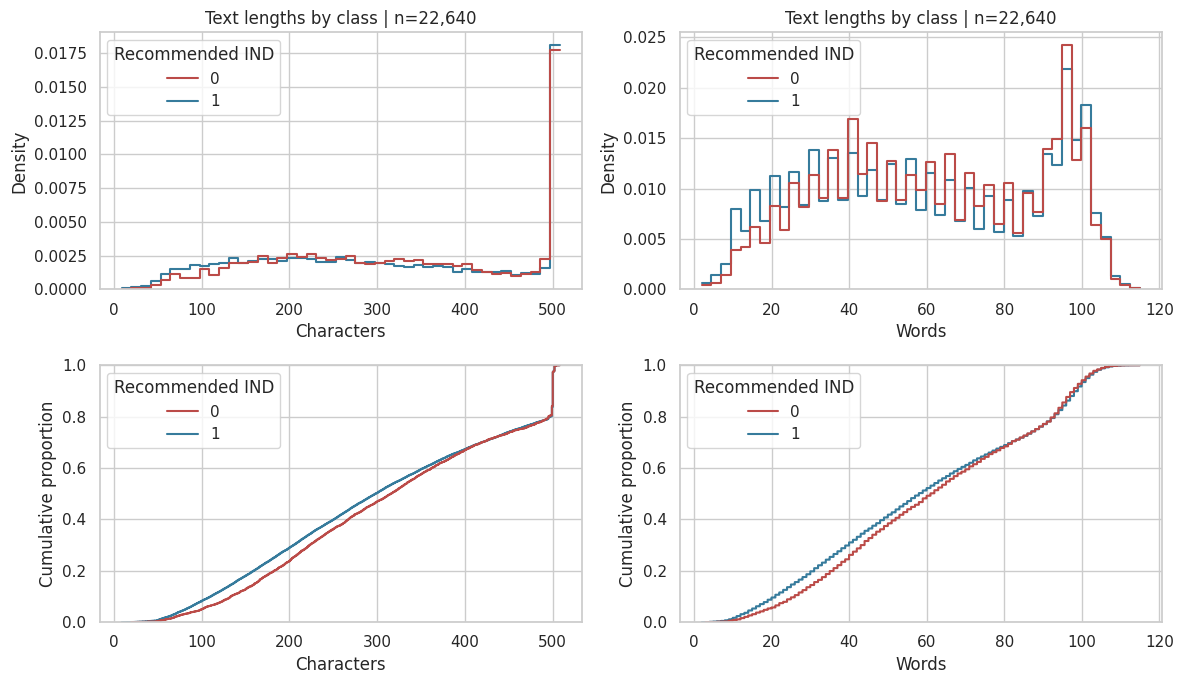

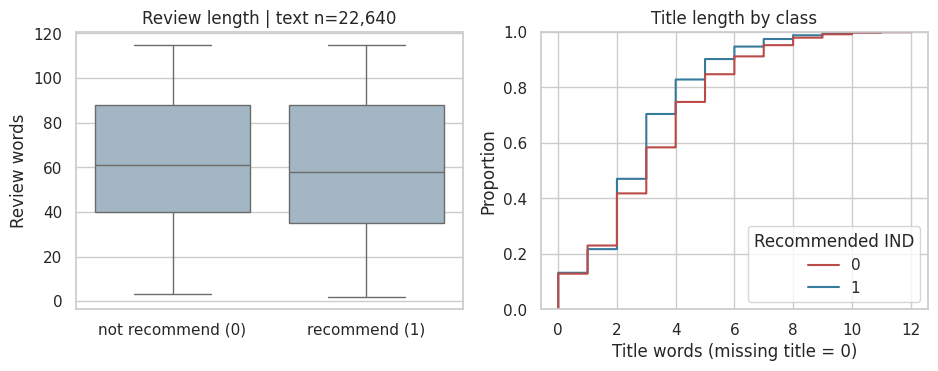

,rows,dataset_pct,not_recommend_n,not_recommend_pct,has_title_pct
max_words,,,,,
3,18,0.079505,2,11.111111,66.666667
5,52,0.229682,5,9.615385,67.307692
10,357,1.576855,37,10.364146,69.187675


,source_row_id,Recommended IND,Title,Review Text,review_words
859,859,1,,Great style!,2
1637,1637,1,Stunning skirt!,Beautiful colors,2
1792,1792,1,,Super cute and flattering!,4
2978,2978,1,,Love embroidery!,2
4102,4102,1,Comfy and unique!,This is awesome multi-season dress.,5
4274,4274,1,,Love this top!,3
4386,4386,1,Great feel,Order a size down,4
4888,4888,1,Absolutely beautiful,Got the green one,4
5925,5925,1,,Beautiful and delicate!!,3
7236,7236,1,,Comfy cozy!,2


,source_row_id,Recommended IND,review_chars,Review Text
17597,17597,1,508,I adore this blouse. the colors are vibrant (see my photo below). this is one of ...
19304,19304,0,508,I have been continually disappointed in retailer's clothing for the past year. i ...
22936,22936,1,507,I love this cotton weave shift dress. it is supposed to be loose and not tight. i...
1974,1974,1,506,One of the things i love most about this dress is that the straps are adjustable....
22010,22010,0,506,"Retailer consistently provides unique, sophisticated and quality made clothing. w..."


Ровно 500 символов: 3,061; >=490: 4,862; максимум: 508.


,source_row_id,review_chars,ending
10732,10732,500,it more confident to wear these outside of the gym then they would be great
16414,16414,500,lat to dry) and it has held up well. i'm definitely bookmarking this to buy
12986,12986,500,"the back, making it awkward to have this very warm dress with neck, upper b"
10358,10358,500,"ed also. i might have sprung for them anyway, they do have a cute shape, bu"
18471,18471,500,"r top (warm-up pullover in charcoal), looked like high couture! the color i"
12088,12088,499,"version. also, the fabric doesn't feel thick but it is very insulating and"


**Наблюдение:** медианы слов у классов 0/1 — 61/58, символов — 316/298. Распределения заметно перекрываются. Отзывов до 5 слов — 52, из них класса 0 — 5; малая группа не позволяет надёжно судить о будущем качестве модели.

In [12]:
length_fields = ["review_chars", "review_words", "title_chars", "title_words"]
length_summary = df.groupby(TARGET)[length_fields].quantile([0, .25, .5, .75, .9, .99, 1])
display(save_table(length_summary, "length_quantiles"))
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for i, field in enumerate(["review_chars", "review_words"]):
    sns.histplot(data=df, x=field, hue=TARGET, hue_order=[0, 1], palette=COLORS,
                 stat="density", common_norm=False, element="step", fill=False, bins=45, ax=axes[0, i])
    axes[0, i].set(title=f"Text lengths by class | n={len(df):,}", xlabel="Characters" if i == 0 else "Words")
    sns.ecdfplot(data=df, x=field, hue=TARGET, hue_order=[0, 1], palette=COLORS, ax=axes[1, i])
    axes[1, i].set(xlabel="Characters" if i == 0 else "Words", ylabel="Cumulative proportion")
fig.tight_layout()
show_figure(fig, "06_review_lengths")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.boxplot(data=df, x="class_label", y="review_words", order=[LABELS[0], LABELS[1]], color="#9db9c8", fliersize=2, ax=axes[0])
axes[0].set(xlabel="", ylabel="Review words", title=f"Review length | text n={len(df):,}")
sns.ecdfplot(data=df, x="title_words", hue=TARGET, hue_order=[0, 1], palette=COLORS, ax=axes[1])
axes[1].set(xlabel="Title words (missing title = 0)", title="Title length by class")
show_figure(fig, "07_title_and_review_lengths")
short_rows = []
for threshold in [3, 5, 10]:
    subset = df[df.review_words.le(threshold)]
    short_rows.append({"max_words": threshold, "rows": len(subset), "dataset_pct": 100 * len(subset) / len(df),
                       "not_recommend_n": int(subset[TARGET].eq(0).sum()),
                       "not_recommend_pct": 100 * subset[TARGET].eq(0).mean(),
                       "has_title_pct": 100 * subset.Title.str.len().gt(0).mean()})
short_table = pd.DataFrame(short_rows).set_index("max_words")
display(save_table(short_table, "short_reviews"))
display(df.loc[df.review_words.le(5), ["source_row_id", TARGET, "Title", "Review Text", "review_words"]].head(12))
longest = df.nlargest(5, "review_chars")
display(longest[["source_row_id", TARGET, "review_chars", "Review Text"]])
near_limit = df[df.review_chars.ge(490)]
print(f"Ровно 500 символов: {df.review_chars.eq(500).sum():,}; >=490: {len(near_limit):,}; максимум: {df.review_chars.max()}.")
display(near_limit[["source_row_id", "review_chars"]].assign(ending=near_limit["Review Text"].str[-75:]).sample(6, random_state=SEED))
display(Markdown(f"**Наблюдение:** медианы слов у классов 0/1 — {df.loc[df[TARGET].eq(0), 'review_words'].median():.0f}/{df.loc[df[TARGET].eq(1), 'review_words'].median():.0f}, символов — {df.loc[df[TARGET].eq(0), 'review_chars'].median():.0f}/{df.loc[df[TARGET].eq(1), 'review_chars'].median():.0f}. Распределения заметно перекрываются. Отзывов до 5 слов — {int(short_table.loc[5, 'rows'])}, из них класса 0 — {int(short_table.loc[5, 'not_recommend_n'])}; малая группа не позволяет надёжно судить о будущем качестве модели."))

In [13]:
length_groups = pd.cut(df.review_words, bins=[0, 5, 20, 50, 100, np.inf],
                       labels=["1-5", "6-20", "21-50", "51-100", "101+"])
length_target = pd.crosstab(length_groups, df[TARGET]).reindex(columns=[0, 1], fill_value=0)
length_target["n"] = length_target[[0, 1]].sum(axis=1)
length_target["not_recommend_pct"] = 100 * length_target[0] / length_target.n
display(save_table(length_target, "length_target"))
# Illustrative selection, not a validated annotation of ambiguity.
mixed_mask = df["Review Text"].str.contains(r"\b(?:love|great|beautiful)\b", case=False, regex=True, na=False) & df["Review Text"].str.contains(r"\b(?:but|however|although)\b", case=False, regex=True, na=False)
display(df.loc[mixed_mask, ["source_row_id", "Rating", TARGET, "Title", "Review Text"]].sample(6, random_state=SEED))

Recommended IND,0,1,n,not_recommend_pct
review_words,,,,
1-5,5,47,52,9.615385
6-20,231,1738,1969,11.731844
21-50,1342,5975,7317,18.340850
51-100,2283,9560,11843,19.277210
101+,240,1219,1459,16.449623


,source_row_id,Rating,Recommended IND,Title,Review Text
1618,1618,2,0,Great quality and color but boxy and ill-fitting,I wanted to love this sweater. the photo of the model makes it look so soft and w...
10263,10263,5,1,Absolutely keeping this one,This is the one. the faux fur i have been looking for. it is plush and heavy so t...
16153,16153,5,1,Extremely attractive,Love the top! this is an attractive black top with a unique back which will match...
18571,18571,5,1,Great going-out top!,"Love this top! however, i'm biased bc i love hd, such originality in their clothi..."
9049,9049,5,1,Go to pattern,"I?m mad for plaid but usually for smaller pattern and winter colors. somehow, thi..."
14621,14621,5,1,Great piece!,I was wavering on this post purchase but then decided to wear it to a store openi...


**Интерпретация и решение.** Сопоставляем распределения, медианы и квантили,
а не делаем вывод о каждом отзыве по средней длине класса. Короткий текст может
быть ясным («love it») или неинформативным; его не следует удалять автоматически.
Заголовок способен добавить контекст, поэтому его объединение с текстом — отдельный эксперимент.

Накопление длин около 500 символов совместимо с ограничением на источнике, но максимум
выше 500 и обрыв окончания не доказывают механизм усечения. Без сведений о сборе это гипотеза.
Примеры с `but/however` — иллюстрации смешанных оценок, а не разметка «сложных объектов».
Неоднозначность рекомендации и эмоциональной окраски требует дальнейшего анализа ошибок.

## 8. Частотные слова и биграммы двух классов

Используем английские буквенные токены; нормализуем регистр и апострофы. `don't`
разворачивается в `do not`, `can't` — в `can not`, `won't` — в `will not`.
Стоп-слова исключаются, **`no/not/nor` сохраняются**. Биграммы составляются из соседних
токенов после раскрытия сокращений; пары со стоп-словом пропускаются, несоседние слова
не склеиваются. Эти решения относятся к описательному анализу, а не закрепляют будущий TF-IDF.

Для сравнения используем долю документов с токеном: большие классы не получают преимущество
из-за числа отзывов. `min_df=10` исключает единичные случайности. Матрица остаётся разреженной.

Sparse matrix: 22,640 reviews × 5,725 terms; nonzero: 611,548.


,target,occurrences,documents,document_pct,ngram
term,,,,,
small,0,910,731,17.824921,1
really,0,869,746,18.190685,1
i'm,0,909,759,18.507681,1
ordered,0,825,763,18.605218,1
it's,0,964,764,18.629603,1
love,0,928,803,19.580590,1
did,0,1001,824,20.092660,1
look,0,965,826,20.141429,1
size,0,1210,923,22.506706,1


,target,occurrences,documents,document_pct,ngram
term,,,,,
small,1,3818,3009,16.230649,1
fabric,1,3549,3132,16.894115,1
perfect,1,3574,3196,17.239333,1
color,1,3888,3419,18.442203,1
just,1,4356,3699,19.952532,1
it's,1,5407,4017,21.667835,1
i'm,1,4972,4062,21.910567,1
like,1,5369,4410,23.787691,1
great,1,5587,4720,25.459841,1


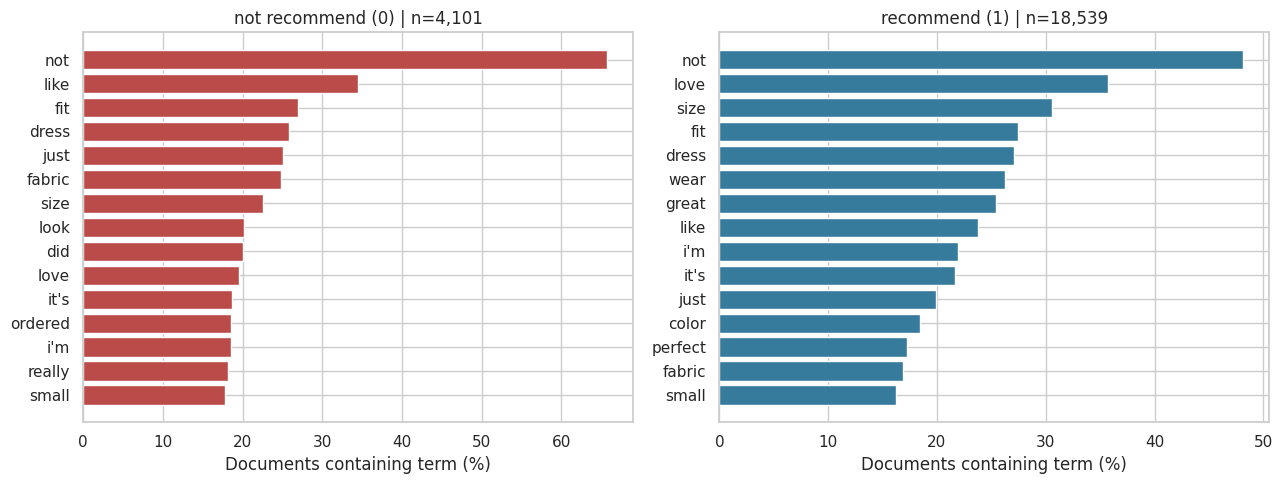

,target,occurrences,documents,document_pct,ngram
term,,,,,
not fit,0,101,94,2.292124,2
i'm not,0,99,97,2.365277,2
not like,0,103,97,2.365277,2
felt like,0,102,98,2.389661,2
usually wear,0,103,103,2.511583,2
not look,0,119,113,2.755426,2
look like,0,119,116,2.828578,2
just did,0,126,119,2.901731,2
looks like,0,141,138,3.365033,2


,target,occurrences,documents,document_pct,ngram
term,,,,,
skinny jeans,1,320,318,1.715303,2
super cute,1,325,319,1.720697,2
size small,1,368,354,1.909488,2
i'm lbs,1,355,355,1.914882,2
highly recommend,1,363,362,1.952640,2
it's not,1,377,364,1.963428,2
usual size,1,413,409,2.206160,2
not wait,1,415,410,2.211554,2
not sure,1,429,420,2.265494,2


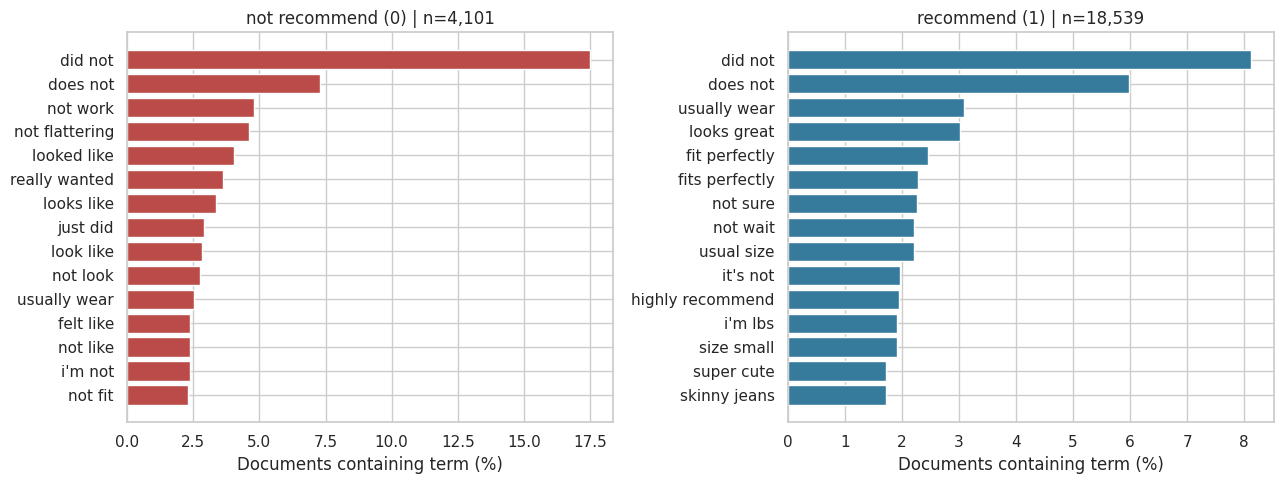

target,docs_0,docs_1,log2_prevalence_ratio_0_vs_1
term,,,
poorly,41,6,4.760930
awful,69,14,4.398360
high hopes,56,12,4.308418
no shape,54,12,4.256888
poor quality,41,9,4.246357
poor,86,23,4.033949
horrible,35,10,3.886461
not worth,84,27,3.778004
shame,50,16,3.760930


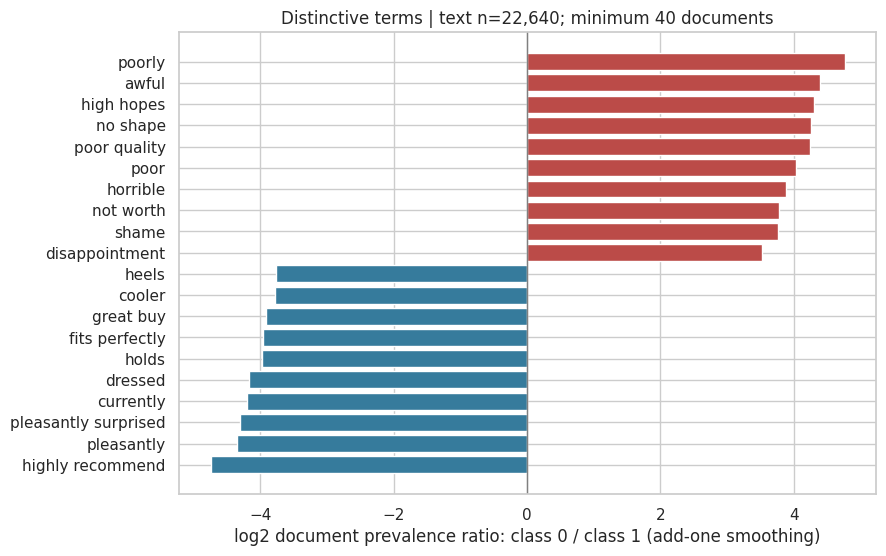

Контекст токена: poorly


,source_row_id,Recommended IND,Review Text
131,131,1,"It's ok, fit doesn't wow me because of my body. chest is too wide, hips look too ..."
381,381,0,Disappointed in the quality of the dress. love the style and especially the color...


Контекст токена: awful


,source_row_id,Recommended IND,Review Text
876,876,1,I just adore this top! it is so comfy and stylish. i wear it with a little purple...
1068,1068,1,I loved this but hesitated to order since i'm petite and busty and assumed it wou...


**Наблюдение:** `not` встречается в 65.7% отзывов класса 0 и 48.1% класса 1, поэтому одно отрицание не определяет метку. `poor quality` и `not worth` чаще связаны с классом 0; `highly recommend` и `fits perfectly` — с классом 1. Среди ассоциаций также есть слова о стиле одежды, например `heels`: частотный анализ отражает состав выборки, а не только отношение к покупке.

In [14]:
stop_words = set(ENGLISH_STOP_WORDS) - {"no", "not", "nor"}

def lexical_tokens(text):
    text = text.lower().replace("’", "'")
    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"\bcan't\b", "can not", text)
    text = re.sub(r"\bcannot\b", "can not", text)
    text = re.sub(r"n't\b", " not", text)
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text)

def terms_analyzer(text):
    tokens = lexical_tokens(text)
    words = [t for t in tokens if t not in stop_words and len(t) > 1]
    pairs = [a + " " + b for a, b in zip(tokens, tokens[1:])
             if a not in stop_words and b not in stop_words and len(a) > 1 and len(b) > 1]
    return words + pairs

assert "not" in terms_analyzer("I don't recommend it")
assert "not recommend" in terms_analyzer("I don't recommend it")
assert "no" in terms_analyzer("no good") and "nor" in terms_analyzer("neither good nor bad")
vectorizer = CountVectorizer(analyzer=terms_analyzer, min_df=10)
X = vectorizer.fit_transform(df["Review Text"])
terms = vectorizer.get_feature_names_out()
term_frames = []
for label in [0, 1]:
    mask = df[TARGET].eq(label).to_numpy()
    counts = np.asarray(X[mask].sum(axis=0)).ravel()
    document_counts = np.asarray((X[mask] > 0).sum(axis=0)).ravel()
    term_frames.append(pd.DataFrame({"term": terms, "target": label, "occurrences": counts,
        "documents": document_counts, "document_pct": 100 * document_counts / mask.sum(),
        "ngram": np.where(np.char.find(terms.astype(str), " ") >= 0, 2, 1)}))
term_stats = pd.concat(term_frames, ignore_index=True)
print(f"Sparse matrix: {X.shape[0]:,} reviews × {X.shape[1]:,} terms; nonzero: {X.nnz:,}.")
for ngram in [1, 2]:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for label, ax in zip([0, 1], axes):
        top = term_stats[(term_stats.target == label) & (term_stats.ngram == ngram)].nlargest(15, "document_pct").sort_values("document_pct")
        ax.barh(top.term, top.document_pct, color=COLORS[label])
        ax.set(xlabel="Documents containing term (%)", title=f"{LABELS[label]} | n={df[TARGET].eq(label).sum():,}")
        display(save_table(top.set_index("term"), f"top_{ngram}gram_class_{label}"))
    fig.tight_layout()
    show_figure(fig, f"08_top_{ngram}grams")
contrast = term_stats.pivot(index="term", columns="target", values="documents").rename(columns={0: "docs_0", 1: "docs_1"})
n0, n1 = [int(df[TARGET].eq(i).sum()) for i in [0, 1]]
contrast["log2_prevalence_ratio_0_vs_1"] = np.log2(((contrast.docs_0 + 1) / (n0 + 2)) / ((contrast.docs_1 + 1) / (n1 + 2)))
contrast = contrast[(contrast.docs_0 + contrast.docs_1).ge(40)]
distinctive = pd.concat([contrast.nlargest(10, "log2_prevalence_ratio_0_vs_1"), contrast.nsmallest(10, "log2_prevalence_ratio_0_vs_1")])
display(save_table(distinctive, "distinctive_terms"))
fig, ax = plt.subplots(figsize=(9, 6))
distinctive = distinctive.sort_values("log2_prevalence_ratio_0_vs_1")
ax.barh(distinctive.index, distinctive.log2_prevalence_ratio_0_vs_1,
        color=[COLORS[0] if x > 0 else COLORS[1] for x in distinctive.log2_prevalence_ratio_0_vs_1])
ax.axvline(0, color="grey", linewidth=1)
ax.set(xlabel="log2 document prevalence ratio: class 0 / class 1 (add-one smoothing)",
       title=f"Distinctive terms | text n={len(df):,}; minimum 40 documents")
show_figure(fig, "09_distinctive_terms")
for term in contrast.nlargest(2, "log2_prevalence_ratio_0_vs_1").index:
    print("Контекст токена:", term)
    examples = df.loc[df["Review Text"].str.contains(re.escape(term), case=False, na=False), ["source_row_id", TARGET, "Review Text"]]
    display(examples.head(2))
not_rates = term_stats[term_stats.term.eq("not")].set_index("target").document_pct
display(Markdown(f"**Наблюдение:** `not` встречается в {not_rates.loc[0]:.1f}% отзывов класса 0 и {not_rates.loc[1]:.1f}% класса 1, поэтому одно отрицание не определяет метку. `poor quality` и `not worth` чаще связаны с классом 0; `highly recommend` и `fits perfectly` — с классом 1. Среди ассоциаций также есть слова о стиле одежды, например `heels`: частотный анализ отражает состав выборки, а не только отношение к покупке."))

**Вывод.** Частые слова могут описывать одежду в обоих классах. Отличительные
слова проверяем по относительной распространённости и контексту. Сглаженное отношение
частот — описательная ассоциация, а не причинный эффект и не важность признака модели.
Сочетания с отрицаниями дают основание проверить n-граммы в будущем TF-IDF;
векторизатор и отбор признаков при обучении должны обучаться заново только на train.

## 9. Попарные распределения, корреляции и сводные таблицы

Для pairplot берём воспроизводимую стратифицированную подвыборку до 2 500 строк,
сохраняя исходный дисбаланс. Корреляции Spearman считаем на всей текстовой выборке;
это монотонные связи, а не доказательства причинности. Числовой код товара и индекс
исключаем. Рейтинг и отклики помечены как запрещённые входы основной модели.

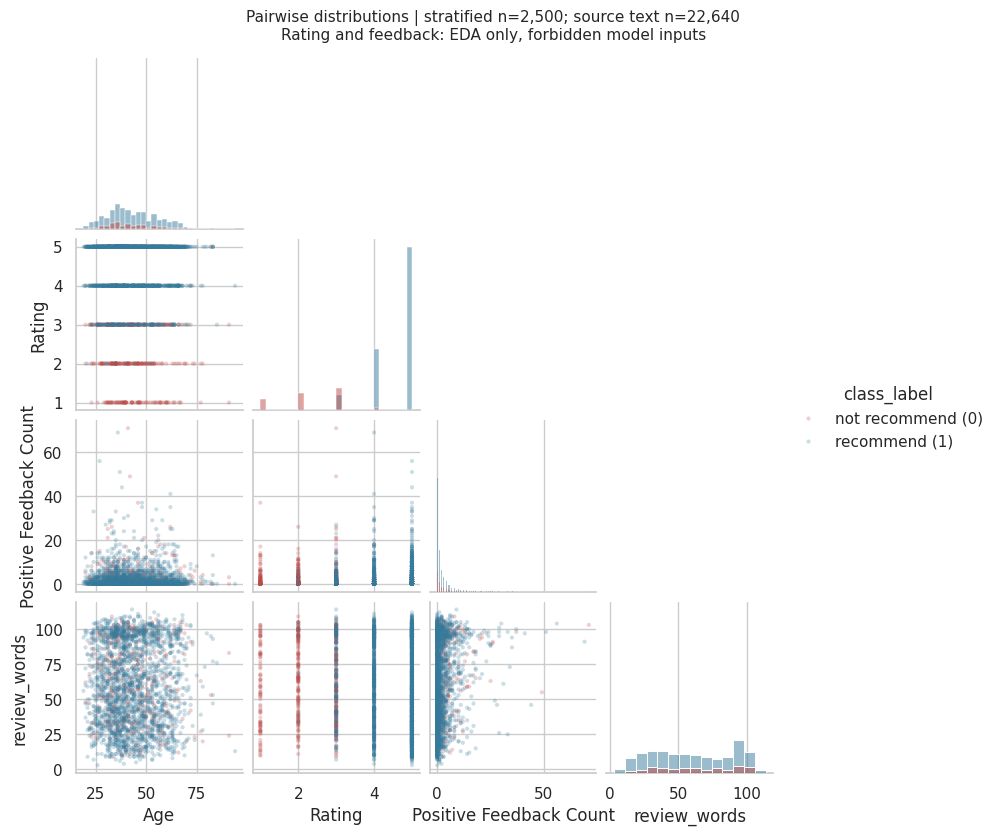

,Age,Rating,Positive Feedback Count,review_chars,review_words,title_chars,Recommended IND
Age,1.000000,0.033654,0.071609,0.013999,0.013037,-0.009373,0.034725
Rating,0.033654,1.000000,-0.059558,-0.072813,-0.077798,-0.076811,0.696496
Positive Feedback Count,0.071609,-0.059558,1.000000,0.253396,0.246398,0.066407,-0.074531
review_chars,0.013999,-0.072813,0.253396,1.000000,0.984263,0.267803,-0.030813
review_words,0.013037,-0.077798,0.246398,0.984263,1.000000,0.258778,-0.028842
title_chars,-0.009373,-0.076811,0.066407,0.267803,0.258778,1.000000,-0.039020
Recommended IND,0.034725,0.696496,-0.074531,-0.030813,-0.028842,-0.039020,1.000000


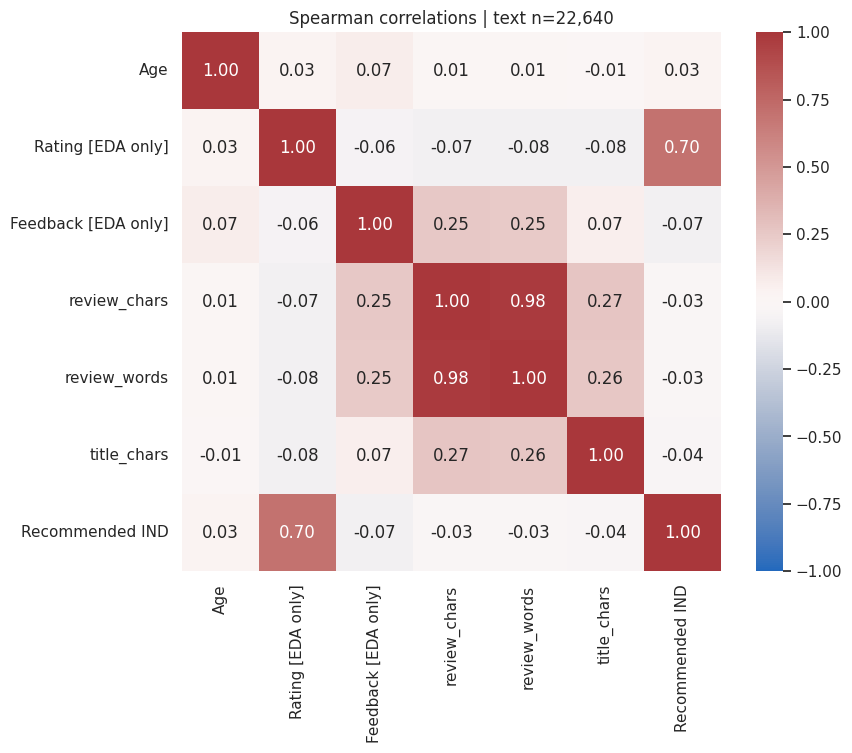

size         median      
Recommended IND       0       1      0     1
Department Name                             
Bottoms           551.0  3110.0   67.0  59.0
Dresses          1197.0  4948.0   66.0  66.0
Intimate          254.0  1399.0   60.5  51.0
Jackets           167.0   835.0   66.0  66.0
Tops             1902.0  8146.0   56.0  54.0
Trend              30.0    88.0   67.0  71.5
unknown             NaN    13.0    NaN  32.0

In [15]:
pair_fields = ["Age", "Rating", "Positive Feedback Count", "review_words"]
pair_sample = pd.concat([
    group.sample(n=min(len(group), max(1, round(2500 * len(group) / len(df)))), random_state=SEED)
    for _, group in df.groupby(TARGET)
])
grid = sns.pairplot(pair_sample[pair_fields + ["class_label"]], hue="class_label",
    hue_order=[LABELS[0], LABELS[1]], palette=[COLORS[0], COLORS[1]],
    diag_kind="hist", corner=True, height=2,
    plot_kws={"s": 9, "alpha": .25, "linewidth": 0}, diag_kws={"common_norm": False})
grid.figure.suptitle(f"Pairwise distributions | stratified n={len(pair_sample):,}; source text n={len(df):,}\nRating and feedback: EDA only, forbidden model inputs", y=1.04, fontsize=11)
show_figure(grid.figure, "10_pairplot")
corr_fields = ["Age", "Rating", "Positive Feedback Count", "review_chars", "review_words", "title_chars", TARGET]
correlation = df[corr_fields].corr(method="spearman")
display(save_table(correlation, "spearman_correlations"))
fig, ax = plt.subplots(figsize=(9, 7))
renamed = {"Rating": "Rating [EDA only]", "Positive Feedback Count": "Feedback [EDA only]"}
sns.heatmap(correlation.rename(index=renamed, columns=renamed), annot=True, fmt=".2f", center=0,
            vmin=-1, vmax=1, cmap="vlag", square=True, ax=ax)
ax.set(title=f"Spearman correlations | text n={len(df):,}")
show_figure(fig, "11_spearman_correlations")
display(pd.pivot_table(df, index="Department Name", columns=TARGET, values="review_words", aggfunc=["size", "median"], observed=True))

**Решение.** Связанные длины в символах и словах описывают близкие свойства текста.
Связь рейтинга с рекомендацией не делает рейтинг допустимым признаком: он запрещён
условиями проекта. Возраст и длина могут отличаться по классам, но не позволяют
сами по себе утверждать предсказательное качество. Категории нельзя кодировать
произвольными числами ради Pearson/Spearman; их связи показаны групповыми долями.

## 10. Итоговые выводы, практическая применимость и следующие этапы

В итогах связываем наблюдения с конкретными решениями. Числа ниже вычисляются заново
из данных, а не вставляются вручную. Сводные таблицы содержат агрегаты; полный корпус
и локальный манифест строк в Git не попадают.

In [16]:
summary = {
    "source_sha256": source_hash, "seed": SEED, "python": platform.python_version(), "versions": versions,
    "raw_rows": len(raw), "text_rows": len(df),
    "raw_class_counts": {str(k): int(v) for k, v in audit[TARGET].value_counts().items()},
    "text_class_counts": {str(k): int(v) for k, v in df[TARGET].value_counts().items()},
    "missing_text": int(audit["Review Text"].isna().sum()), "missing_title": int(audit["Title"].isna().sum()),
    "missing_cells_pct": cell_missing_pct, "incomplete_rows": incomplete_rows,
    "full_duplicates_raw": int(full_duplicate_mask.sum()), "removed_text_duplicates": before_dedup - len(df),
    "repeated_text_groups_raw": len(repeated_texts), "conflicting_text_groups_raw": int(repeated_texts.labels.gt(1).sum()),
    "text_medians_words": {str(k): float(v) for k, v in df.groupby(TARGET).review_words.median().items()},
    "text_medians_chars": {str(k): float(v) for k, v in df.groupby(TARGET).review_chars.median().items()},
    "exact_500_chars": int(df.review_chars.eq(500).sum()), "max_review_chars": int(df.review_chars.max()),
    "rating_target_mismatch": len(contradictions), "short_reviews_5_words": int(df.review_words.le(5).sum()),
    "class_rare_groups": category_tables["Class Name"].query("n < 30").reset_index().to_dict(orient="records"),
    "missing_text_pct_by_target": {str(k): float(v) for k, v in missing_by_target.missing_text_pct.items()},
    "spearman_target": {k: float(v) for k, v in correlation[TARGET].drop(TARGET).items()},
    "figures": sorted(p.name for p in FIGURES.glob("*.png")),
}
(TABLES / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
median0, median1 = [df.loc[df[TARGET].eq(i), "review_words"].median() for i in [0, 1]]
conclusions = pd.DataFrame([
    ("Дисбаланс", f"Класс 0: {df[TARGET].eq(0).mean():.2%} текстовой выборки", "Macro-F1, F1 класса 0; PR-AUC с положительным классом 0"),
    ("Пустой текст", f"{summary['missing_text']} строк", "Исключить из text-only; не восстанавливать таргет по рейтингу"),
    ("Повторные записи", f"{summary['removed_text_duplicates']} полный дубль удалён; {len(repeated_texts)} текстовых групп в сыром наборе", "Сохранять исходные ID; учитывать группы при будущем split"),
    ("Длина", f"Медианы слов: класс 0 — {median0:.0f}, класс 1 — {median1:.0f}", "Проверить качество отдельно по длинам; короткие тексты сохранять"),
    ("Категории", "Есть группы с единицами наблюдений", "Показывать n; unknown; проверить текст + категория на следующих этапах"),
    ("Слова и отрицания", "Частоты/контексты отличаются по классам", "Проверить TF-IDF с n-граммами, сохранять смысл отрицаний"),
    ("Рейтинг и рекомендация", f"{len(contradictions)} явных несовпадений высокой/низкой оценки и метки", "Не исправлять метку по рейтингу; рейтинг запрещён модели"),
], columns=["observation", "evidence", "action"]).set_index("observation")
display(save_table(conclusions, "conclusions"))
display(Markdown(f"**Итоговая текстовая выборка: {len(df):,} строк.** Исключено {len(raw)-len(df):,}; исходный CSV сохранён без изменений."))

def md_table(headers, rows):
    return "\n".join(["| " + " | ".join(headers) + " |",
                       "| " + " | ".join(["---"] * len(headers)) + " |",
                       *["| " + " | ".join(map(str, row)) + " |" for row in rows]])

ledger_md = md_table(["Этап", "Строк", "Исключено", "Рекомендаций, %"],
    [(row["stage"], f"{row['rows']:,}", row["removed"], f"{row['recommend_pct']:.2f}") for row in ledger])
category_md = md_table(["Отдел", "n", "Рекомендаций, %", "Wilson 95%, %"],
    [(name, f"{int(row.n):,}", f"{row.recommend_pct:.2f}", f"{row.wilson_low_pct:.2f}–{row.wilson_high_pct:.2f}")
     for name, row in category_tables["Department Name"].iterrows()])
short_md = md_table(["Максимум слов", "n", "Класс 0, n", "Класс 0, %"],
    [(threshold, int(row.rows), int(row.not_recommend_n), f"{row.not_recommend_pct:.2f}") for threshold, row in short_table.iterrows()])

report = f'''# Review Decoder — результаты чекпоинта 2

## Постановка и воспроизводимость

Бинарная классификация английского отзыва: `Recommended IND = 1` — рекомендация, `0` — её отсутствие. Результат проекта должен описывать вероятность рекомендации покупательницей, а не объективное качество товара или универсальную тональность текста.

[Источник и схема данных](../docs/dataset.md) · [Выполненный ноутбук](../notebooks/01_eda.ipynb) · [Машиночитаемая сводка](tables/summary.json).

Исходный файл: {len(raw):,} строк, 10 содержательных полей и индекс экспорта. Контрольная сумма SHA-256: `{source_hash}`. Python {platform.python_version()}, pandas {versions['pandas']}, scikit-learn {versions['scikit-learn']}, seed {SEED}. Команда из корня: `.venv/Scripts/python.exe scripts/run_eda.py`. Ноутбук и этот отчёт восстанавливаются из CSV; окружение, исходник и локальные манифесты исключены из Git.

EDA использует весь датасет. Тестовая часть для моделей здесь не выделяется, и будущий test из этих данных нельзя называть полностью неизученным. Подбор признаков и моделей далее должен выполняться внутри train; одинаковые тексты не должны попадать в разные части разбиения.

## Качество данных и подготовка

В исходной таблице отсутствуют {summary['missing_title']:,} заголовков ({100 * summary['missing_title'] / len(raw):.2f}%), {summary['missing_text']} основных текстов ({100 * summary['missing_text'] / len(raw):.2f}%) и по 14 значений каждого уровня категории (0,06%). Пропусков в остальных полях не обнаружено. Общая доля пустых ячеек без индекса — {cell_missing_pct:.2f}%; неполных строк — {incomplete_rows:,} ({100 * incomplete_rows / len(raw):.2f}%). Подробности: [таблица пропусков](tables/missing_values.csv), [сочетания](tables/missing_patterns.csv).

Текст отсутствует у {missing_by_target.loc[0, 'missing_text_pct']:.2f}% класса 0 и {missing_by_target.loc[1, 'missing_text_pct']:.2f}% класса 1. χ² даёт p≈4,12×10⁻¹³, но Cramér's V≈0,047 показывает небольшой эффект. Для заголовка V≈0,024. Поэтому пропуски связаны с таргетом, но причина не установлена. Гипотеза об оценке без текста совместима с данными; доказать механизм сбора по CSV нельзя. Лишь одна строка без основного текста имеет заголовок, поэтому заголовок не восстановит большинство пустых отзывов. [Проверка гипотез](tables/missingness_hypotheses.csv).

![Пропуски](figures/01_missing_values.png)

Ошибок по проверенным доменам не найдено: таргет 0/1, рейтинг 1–5, возраст 18–99, идентификаторы неотрицательные целые, отклики 0–122. [Проверки](tables/domain_checks.csv) не доказывают отсутствие любых ошибок: семантическую корректность каждого текста и возраста по CSV установить нельзя.

Обнаружен 21 полный повтор без индекса экспорта; только один относится к непустому отзыву. В сыром наборе шесть групп совпадающего нормализованного текста без конфликтующих меток. Полное совпадение всех полей рассматривается как кандидат на повторный экспорт: удаление одного повтора — явное допущение, а не доказанная история происхождения. Совпадения текста при различающихся полях сохранены.

{ledger_md}

У строк без текста сохраняется место в аудите, но они исключены из text-only выборки. Отсутствующий заголовок заменён пустой строкой, категория — `unknown`; исходные пропуски сохранены отдельными флагами. Оставлена исходная метка `Initmates`. Исходный CSV не изменён; числовой импутации и обрезки не применялось. [Журнал обработки](tables/cleaning_ledger.csv).

## Баланс классов

До обработки: {summary['raw_class_counts']['1']:,} рекомендаций (82,24%) и {summary['raw_class_counts']['0']:,} нерекомендаций (17,76%). После обработки: {summary['text_class_counts']['1']:,} рекомендаций ({100 * df[TARGET].mean():.2f}%) и {summary['text_class_counts']['0']:,} нерекомендация ({100 * df[TARGET].eq(0).mean():.2f}%). Постоянный ответ класса большинства даст высокую accuracy, не распознавая класс 0. Это ориентир дисбаланса, а не оценка обученной модели на тесте.

Основная метрика будущих экспериментов — Macro-F1, дополнительно F1 класса 0 и PR-AUC с положительным классом `not recommend`: `y_negative = (y == 0)`, вероятность класса 0. Также ROC-AUC с явно указанным классом и confusion matrix. Ресэмплинг в EDA не применялся.

![Баланс классов](figures/02_class_balance.png)

## Числовые признаки и выбросы

IQR-фильтр отметил бы 108 возрастов выше 79 лет, 2 147 больших значений откликов и 2 370 рейтингов 1–2. Низкие оценки оказываются «выбросами» из-за преобладания оценок 4–5; их удаление исказило бы задачу. Крайние значения возраста и откликов допустимы по домену; после просмотра примеров они сохранены. Большие отклики отображаются через `log1p` только на графике. [Кандидаты по IQR](tables/outlier_candidates.csv).

Встречаются {len(contradictions)} случаев рейтинга 1–2 с рекомендацией или рейтинга 4–5 без неё. Оценка и рекомендация связаны, но не тождественны: заменять метку по рейтингу нельзя. Spearman с таргетом для рейтинга — {correlation.loc['Rating', TARGET]:.3f}, возраста — {correlation.loc['Age', TARGET]:.3f}, откликов — {correlation.loc['Positive Feedback Count', TARGET]:.3f}. Сильная связь рейтинга не отменяет запрет использовать его в основной модели.

`Clothing ID` описывает товар, а не упорядоченную величину. В сыром наборе {len(item_counts):,} товаров; на 10 самых обсуждаемых приходится {100 * item_counts.head(10).sum() / len(audit):.2f}% отзывов. Концентрация может влиять на оценку переноса на новые товары; идентификатор допустим для диагностического группирования, но не как вход основной модели.

## Категории одежды

{category_md}

Разница между отделами даёт основание проверить «текст + категория» в следующих экспериментах. Это пока не доказательство выигрыша модели. В текстовой выборке у `Casual bottoms` и `Chemises` по одному примеру, у `unknown` — 13. Доля 100% там сопровождается широким интервалом и не означает надёжного преимущества категории. Интервалы Wilson описательные и предполагают независимость наблюдений; общие товары и авторы могут нарушать это предположение.

![Категории и размеры групп](figures/05_class_name.png)

## Длины, короткие и неоднозначные отзывы

Медиана основного текста у класса 0 — {median0:.0f} слово / {summary['text_medians_chars']['0']:.0f} символов, у класса 1 — {median1:.0f} слов / {summary['text_medians_chars']['1']:.0f} символов. Распределения значительно перекрываются; Spearman длины в словах с таргетом всего {correlation.loc['review_words', TARGET]:.3f}. По одной длине нельзя судить о рекомендации конкретного отзыва. [Квантили](tables/length_quantiles.csv).

![Длины по классам](figures/06_review_lengths.png)

{short_md}

Порог 5 слов предварительный: таких отзывов только {summary['short_reviews_5_words']}, нерекомендаций — пять. Это маленькая группа; короткие тексты могут быть содержательными и сохраняются. Заголовки часто добавляют контекст, поэтому «заголовок + текст» остаётся отдельным экспериментом.

Ровно 500 символов имеют {summary['exact_500_chars']:,} отзывов ({100 * summary['exact_500_chars'] / len(df):.2f}%), максимум — {summary['max_review_chars']}. Накопление около 500 и окончания некоторых текстов совместимы с ограничением источника, но без описания сбора усечение не доказано. Максимальный ввод сервиса не должен автоматически равняться 500.

В ноутбуке рассмотрены низкие/высокие оценки с неожиданной рекомендацией, короткие отзывы и тексты с `love/great/beautiful` вместе с `but/however/although`. Последние — иллюстративная выборка смешанных мнений, а не валидированная разметка сложности.

## Слова, биграммы и отрицания

Частоты нормированы по числу документов класса; единичные токены отсечены `min_df=10`. Отрицания `no/not/nor` сохранены; отрицательные сокращения развёрнуты. Биграммы строятся по соседним токенам без склейки через удалённые стоп-слова. Матрица частот разреженная, её обучение на всём наборе относится только к EDA; будущий TF-IDF обучается заново внутри train.

`not` есть в {not_rates.loc[0]:.1f}% класса 0 и {not_rates.loc[1]:.1f}% класса 1: само присутствие отрицания не определяет метку. `poor quality`, `not worth`, `awful` чаще связаны с нерекомендацией; `highly recommend`, `fits perfectly`, `pleasantly surprised` — с рекомендацией. Среди положительных ассоциаций встречаются слова вроде `heels`: это также состав ассортимента, а не только тональность. Отношение частот не является причинным эффектом или важностью обученной модели.

![Отличительные слова и сочетания](figures/09_distinctive_terms.png)

## Попарные связи

Pairplot построен на стратифицированной подвыборке {len(pair_sample):,} строк с seed {SEED}, а корреляции Spearman — на всех {len(df):,} текстовых строках. Числовой код товара и индекс не включены; категории не превращались в произвольные числовые коды. Длины в символах и словах сильно связаны, а связь длины с таргетом слаба. [Корреляции](tables/spearman_correlations.csv), [pairplot](figures/10_pairplot.png).

![Корреляции](figures/11_spearman_correlations.png)

## Решения для следующих этапов и ограничения

1. Использовать {len(df):,} непустых отзывов после явного удаления одного полного повтора; сохранять исходные идентификаторы и текстовые группы. В будущем зафиксировать разбиение с учётом групп и дисбаланса до обучения pipeline.
2. Обучить `DummyClassifier`, затем `TF-IDF + LogisticRegression`; отдельно сравнить текст с текстом + категорией. Рейтинг, отклики и ID товара запрещены основной модели; возраст не входит в запланированный сервис.
3. Проверить n-граммы, отрицания, объединение заголовка и текста, качество по длинам и редким категориям. Пропуск заголовка не должен удалять строку, пропуск категории должен поддерживаться через unknown.
4. Для сервиса отклонять пустой/пробельный ввод, поддерживать отсутствие категории и проверять ограничения длины на реальном pipeline. Вероятности должны исходить из вероятностной модели либо калибровки; одна статистика EDA их не даёт.
5. Учитывать данные одного англоязычного магазина, концентрацию на товарах, отсутствие временных меток и идентификаторов авторов. Перенос на другие языки, магазины и периоды не проверен. Причины пропусков и возможное усечение остаются гипотезами.

Подробная связь «наблюдение → доказательство → действие» сохранена в [таблице выводов](tables/conclusions.csv). Обучение моделей, измерение их качества и сервис в этот чекпоинт не входят.
'''
(ROOT / "reports" / "checkpoint-2.md").write_text(report, encoding="utf-8")
print("Сохранён отчёт reports/checkpoint-2.md")

,evidence,action
observation,,
Дисбаланс,Класс 0: 18.11% текстовой выборки,"Macro-F1, F1 класса 0; PR-AUC с положительным классом 0"
Пустой текст,845 строк,Исключить из text-only; не восстанавливать таргет по рейтингу
Повторные записи,1 полный дубль удалён; 6 текстовых групп в сыром наборе,Сохранять исходные ID; учитывать группы при будущем split
Длина,"Медианы слов: класс 0 — 61, класс 1 — 58",Проверить качество отдельно по длинам; короткие тексты сохранять
Категории,Есть группы с единицами наблюдений,Показывать n; unknown; проверить текст + категория на следующих этапах
Слова и отрицания,Частоты/контексты отличаются по классам,"Проверить TF-IDF с n-граммами, сохранять смысл отрицаний"
Рейтинг и рекомендация,296 явных несовпадений высокой/низкой оценки и метки,Не исправлять метку по рейтингу; рейтинг запрещён модели


**Итоговая текстовая выборка: 22,640 строк.** Исключено 846; исходный CSV сохранён без изменений.

Сохранён отчёт reports/checkpoint-2.md


### Ограничения и практическое применение

- Прогноз относится к вероятности рекомендации покупательницей, а не к объективному
  качеству вещи или универсальной тональности отзыва. Оценка и рекомендация могут расходиться.
- Данные одного магазина на английском языке не доказывают переносимость на другие
  магазины, языки, ассортимент и современные пользовательские тексты. Нет времени
  публикации и пользовательского ID: временной дрейф и повторные авторы не проверены.
- Для будущего сервиса пустой/пробельный ввод нужно отклонять. Короткие отзывы допустимы,
  но дают меньше контекста; качество на них нужно измерять отдельно. Предел длины ввода
  задаётся после проверки будущего pipeline, а не автоматически равняется 500 символам.
- При отсутствии категории сервис должен поддерживать `unknown` или text-only вариант;
  возраст, рейтинг, отклики и идентификатор товара пользователю вводить не требуется.
- Следующий чекпоинт: зафиксировать групповое разбиение с учётом классов, обучить
  `DummyClassifier` и `TF-IDF + LogisticRegression`. Векторизатор обучать только на train;
  порог/гиперпараметры выбирать без обращения к test. Этот EDA уже изучил полный датасет.
- Статистические связи не доказывают причинность или выигрыш модели. Необходимы
  отдельная оценка качества, анализ ошибок и затем проверка калибровки вероятностей.

**Критерий воспроизводимости:** все ячейки выполняются последовательно с нового ядра;
таблицы, рисунки и контрольная сумма восстанавливаются. Источники, окружение и
манифест строк локальные, ноутбук и агрегированные результаты доступны для сдачи.